<a href="https://colab.research.google.com/github/Yadkomateo/Desercion_escolar_ACA1/blob/main/ACA1_Desercion_Limpieza_y_Modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ACA N° 1 – Aprendizaje Automático (CUN)
**Predicción de deserción estudiantil con ML clásico** · Especialización en IA · Docente: Dr. Hamilton Rivera Flor

**Integrantes:** _completar_  ·  **Pilar:** Educación  ·  **Dataset:** UCI *Predict Students Dropout and Academic Success*

> Este notebook cubre **limpieza de datos (20 %)** y **modelo ML tradicional + métricas (20 % + 15 %)**.
> La sección de EDA visual y la app de Streamlit las completan otros integrantes con los artefactos que se generan al final.

### Decisiones de diseño (validar con el grupo antes de entregar)
| # | Decisión | Valor | Por qué |
|---|---|---|---|
| 1 | Variable objetivo | `Target` con 3 clases (Dropout / Enrolled / Graduate) | Es el problema original del dataset; "Enrolled" es la clase difícil |
| 2 | Métrica principal | **F1 macro** (+ recall de *Dropout*) | Con clases desbalanceadas, accuracy engaña; en prevención importa no perder desertores |
| 3 | Desbalance | `class_weight="balanced"` | SMOTE interpola entre vectores one-hot y genera categorías inexistentes |
| 4 | Códigos de categoría | Tratados como **nominales** (one-hot), no como números | `course=9500` no es "mayor" que `course=33` |
| 5 | Outliers | Se auditan pero **no se eliminan** | Son estudiantes adultos reales, no errores de captura |
| 6 | Variables del 2.º semestre | `USAR_2DO_SEM = True` | Mejora el modelo, pero implica predecir **tarde** (ver sección 7) |
| 7 | Validación | Split 80/20 estratificado + CV estratificada de 5 folds, semilla 42 | El test se usa **una sola vez** al final |

**Referencia del dataset (APA 7):** Martins, M. V., Real, M. B., Machado, J., & Becker, A. (2021). *UCI Predict Students Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

## 0. Configuración

In [1]:
import re, io, json, zipfile, warnings, platform
from pathlib import Path
from urllib.request import urlopen, Request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, recall_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# ---- Parámetros del proyecto: se cambian AQUÍ, no en medio del código ----
SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
USAR_2DO_SEM = True    # False = solo información disponible tras el 1.er semestre (modelo "preventivo")
MIN_FREQ_CAT = 0.01    # categorías con <1 % de frecuencia se agrupan como "infrecuente"
ARTEFACTOS = Path("artefactos"); ARTEFACTOS.mkdir(exist_ok=True)

print(f"python {platform.python_version()} | sklearn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

python 3.13.16 | sklearn 1.6.1 | pandas 2.2.3 | numpy 2.1.3


## 1. Carga de datos
Orden de búsqueda: archivo local `data.csv` → **UCI (fuente oficial)** → espejo en GitHub.
Si estás en Colab y nada de lo anterior funciona, sube `data.csv` desde el panel de archivos (ícono de carpeta).

In [4]:
URL_UCI = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
URL_ESPEJO = "https://raw.githubusercontent.com/ranga4all1/student-dropout-and-success-prediction/main/data/dataset.csv"


def leer_csv(fuente):
    """Lee el CSV detectando el separador (UCI usa ';', el espejo usa ',')."""
    raw = fuente.read() if hasattr(fuente, "read") else Path(fuente).read_bytes()
    texto = raw.decode("utf-8-sig")
    primera = texto.splitlines()[0]
    sep = ";" if primera.count(";") > primera.count(",") else ","
    return pd.read_csv(io.StringIO(texto), sep=sep)


def leer_zip(contenido: bytes):
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        nombre = next(n for n in z.namelist() if n.lower().endswith(".csv"))
        with z.open(nombre) as f:
            return leer_csv(io.BytesIO(f.read()))


def descargar(url):
    req = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(req, timeout=60) as r:
        return r.read()


def cargar_dataset():
    for local in (Path("data.csv"), Path("data/data.csv")):
        if local.exists():
            print(f"Fuente: archivo local {local}")
            return leer_csv(local)
    try:
        print("Fuente: UCI (oficial)")
        return leer_zip(descargar(URL_UCI))
    except Exception as e:
        print(f"  UCI no disponible ({type(e).__name__}); usando espejo de GitHub")
    try:
        return leer_csv(io.BytesIO(descargar(URL_ESPEJO)))
    except Exception as e:
        raise RuntimeError("No pude descargar el dataset. Sube 'data.csv' al entorno y vuelve a ejecutar.") from e


df_raw = cargar_dataset()
assert df_raw.shape == (4424, 37), f"Dimensiones inesperadas: {df_raw.shape} (se esperaba 4424 x 37)"
print("Dimensiones:", df_raw.shape)
df_raw.head(3)

Fuente: UCI (oficial)
Dimensiones: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


## 2. Limpieza y auditoría de calidad  _(responsable: ver rúbrica, 20 %)_
Primero **estandarizo nombres** (snake_case, corrijo el typo original `Nacionality`) y **clasifico cada columna por su naturaleza real**,
porque en este dataset casi todo viene como número aunque no lo sea.

In [5]:
def limpiar_nombre(c):
    c = c.strip().lower().replace("nacionality", "nationality").replace("'", "")
    return re.sub(r"[^a-z0-9]+", "_", c).strip("_")


df = df_raw.copy()
mapa_columnas = {orig.strip(): limpiar_nombre(orig) for orig in df_raw.columns}
df.columns = list(mapa_columnas.values())

TARGET = "target"
COL_NOMINALES = ["marital_status", "application_mode", "course", "previous_qualification", "nationality",
                 "mothers_qualification", "fathers_qualification", "mothers_occupation", "fathers_occupation"]
COL_BINARIAS = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
                "tuition_fees_up_to_date", "gender", "scholarship_holder", "international"]
COL_NUMERICAS = [c for c in df.columns if c not in COL_NOMINALES + COL_BINARIAS + [TARGET]]
if not USAR_2DO_SEM:
    COL_NUMERICAS = [c for c in COL_NUMERICAS if "2nd_sem" not in c]

assert set(COL_NOMINALES + COL_BINARIAS).issubset(df.columns), "Algún nombre de columna cambió"
print(f"Nominales: {len(COL_NOMINALES)} | Binarias: {len(COL_BINARIAS)} | Numéricas: {len(COL_NUMERICAS)}")
print("Binarias con exactamente 2 valores:", bool((df[COL_BINARIAS].nunique() == 2).all()))

Nominales: 9 | Binarias: 8 | Numéricas: 19
Binarias con exactamente 2 valores: True


In [6]:
print("Nulos totales   :", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
dist = df[TARGET].value_counts()
display(pd.DataFrame({"n": dist, "%": (dist / len(df) * 100).round(1)}))

Nulos totales   : 0
Filas duplicadas: 0


,n,%
target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


[texto del enlace](https://)**Lectura:** si no hay nulos ni duplicados, el dataset ya viene "pre-limpio": Dejamos un `SimpleImputer`
dentro del pipeline como protección (la app de Streamlit podría recibir un campo vacío). El trabajo real de calidad está en los chequeos siguientes.

In [7]:
# Ceros "sospechosos": ¿notas = 0 con unidades matriculadas son datos faltantes disfrazados o información real?
for s in ("1st", "2nd"):
    enr, gr, apr = (f"curricular_units_{s}_sem_{k}" for k in ("enrolled", "grade", "approved"))
    m = (df[enr] > 0) & (df[gr] == 0)
    print(f"[{s} sem] matriculados con nota 0: {m.sum()} ({m.mean():.1%}) | sin matrícula: {(df[enr] == 0).sum()} "
          f"| aprobadas > matriculadas: {(df[apr] > df[enr]).sum()}")
    print("   Target entre los de nota 0:", df.loc[m, TARGET].value_counts(normalize=True).round(3).to_dict())

[1st sem] matriculados con nota 0: 538 (12.2%) | sin matrícula: 180 | aprobadas > matriculadas: 0
   Target entre los de nota 0: {'Dropout': 0.916, 'Enrolled': 0.08, 'Graduate': 0.004}
[2nd sem] matriculados con nota 0: 690 (15.6%) | sin matrícula: 180 | aprobadas > matriculadas: 0
   Target entre los de nota 0: {'Dropout': 0.942, 'Enrolled': 0.058}


,outliers_IQR,%
curricular_units_2nd_sem_grade,877,19.8
curricular_units_1st_sem_grade,726,16.4
curricular_units_1st_sem_credited,577,13.0
application_order,541,12.2
curricular_units_2nd_sem_credited,530,12.0
age_at_enrollment,441,10.0
curricular_units_1st_sem_enrolled,424,9.6
curricular_units_2nd_sem_enrolled,369,8.3
curricular_units_1st_sem_without_evaluations,294,6.6
curricular_units_2nd_sem_without_evaluations,282,6.4


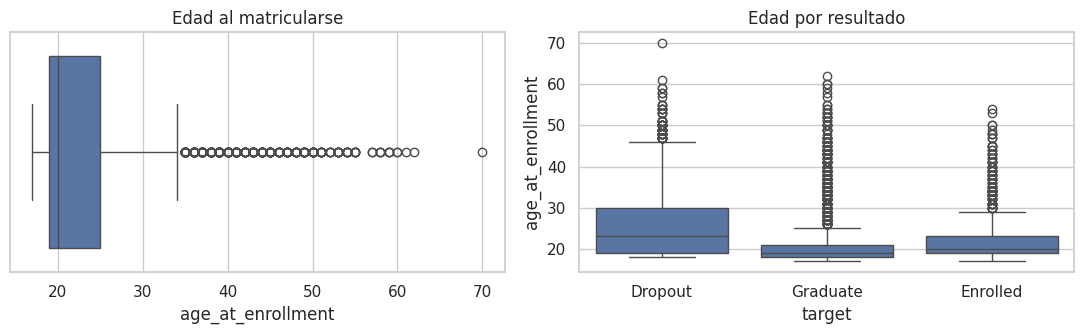

In [8]:
# Outliers (regla IQR) sobre variables numéricas
def conteo_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out = pd.DataFrame({"outliers_IQR": {c: conteo_iqr(df[c]) for c in COL_NUMERICAS}})
out["%"] = (out["outliers_IQR"] / len(df) * 100).round(1)
display(out.sort_values("%", ascending=False).head(10))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df["age_at_enrollment"], ax=ax[0]); ax[0].set_title("Edad al matricularse")
sns.boxplot(data=df, x=TARGET, y="age_at_enrollment", ax=ax[1]); ax[1].set_title("Edad por resultado")
plt.tight_layout(); plt.show()

In [9]:
# Cardinalidad de las nominales: justifica agrupar categorías raras
card = []
for c in COL_NOMINALES:
    fr = df[c].value_counts(normalize=True)
    card.append({"columna": c, "categorias": fr.size, "raras (<%.0f%%)" % (MIN_FREQ_CAT * 100): int((fr < MIN_FREQ_CAT).sum())})
card = pd.DataFrame(card)
display(card)
print(f"Columnas one-hot sin agrupar: {card['categorias'].sum()} | agrupando raras: ~{(card.iloc[:, 1] - card.iloc[:, 2] + 1).sum()}")

,columna,categorias,raras (<1%)
0,marital_status,6,3
1,application_mode,18,9
2,course,17,1
3,previous_qualification,17,12
4,nationality,21,20
5,mothers_qualification,29,21
6,fathers_qualification,34,27
7,mothers_occupation,32,22
8,fathers_occupation,46,34


Columnas one-hot sin agrupar: 220 | agrupando raras: ~80


### Conclusiones de la limpieza
_Cifras de la corrida de referencia; verifícalas contra las salidas de arriba._

- **Calidad base:** 0 nulos y 0 duplicados, así que no hay nada real que imputar. El `SimpleImputer` del pipeline es solo una protección para la app.
- **Los números son categorías:** 9 columnas (`course`, `application_mode`, ocupaciones, etc.) son códigos nominales, por eso van en one-hot. Agrupar categorías con <1 % baja de ≈220 a ≈80 columnas y además absorbe códigos nunca vistos (se prueba al final).
- **Los ceros son señal, no faltantes:** entre los matriculados con nota 0 (≈12 % en el 1.er semestre, ≈16 % en el 2.º), más del 90 % terminó en *Dropout*. Imputarlos o eliminarlos destruiría una de las señales más fuertes del dataset.
- **Outliers:** la regla IQR marca ≈10 % en edad y 16–20 % en las notas. En las notas el "outlier" es en gran parte ese cero informativo; en edad son adultos reales. Se conservan: los árboles son robustos y para regresión logística y SVM se estandariza.
- **Desbalance:** *Enrolled* ≈18 %. Se compensa con `class_weight="balanced"` dentro del modelo, sin datos sintéticos.

## 3. Partición y preprocesamiento (sin fuga de datos)
Todo el preprocesamiento vive **dentro de un `Pipeline`**: se ajusta solo con el set de entrenamiento y se aplica igual al test y a la app.

In [10]:
FEATURES = COL_NOMINALES + COL_BINARIAS + COL_NUMERICAS
X, y = df[FEATURES].copy(), df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
CLASES = sorted(y.unique())
print(f"train: {X_train.shape} | test: {X_test.shape} | clases: {CLASES}")
print("Proporción train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Proporción test :", y_test.value_counts(normalize=True).round(3).to_dict())

train: (3539, 36) | test: (885, 36) | clases: ['Dropout', 'Enrolled', 'Graduate']
Proporción train: {'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.179}
Proporción test : {'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.18}


In [11]:
preprocesador = ColumnTransformer(
    transformers=[
        ("nominales", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_FREQ_CAT, sparse_output=False)),
        ]), COL_NOMINALES),
        ("numericas", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("esc", StandardScaler()),
        ]), COL_NUMERICAS),
        ("binarias", SimpleImputer(strategy="most_frequent"), COL_BINARIAS),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
n_cols = clone(preprocesador).fit(X_train).get_feature_names_out().shape[0]
print(f"Columnas de entrada: {len(FEATURES)}  ->  columnas tras preprocesar: {n_cols}")

Columnas de entrada: 36  ->  columnas tras preprocesar: 106


## 4. Modelado clásico
Siempre contra un **baseline**: si el modelo no lo supera con holgura, no hay nada que defender.
Comparo 4 algoritmos con **validación cruzada estratificada** (solo sobre train) y elijo por F1 macro.

,modelo,accuracy_media,f1_macro_media,recall_macro_media,f1_macro_std
0,Gradient Boosting,0.7728,0.7153,0.7099,0.0268
1,SVM (RBF),0.7544,0.7142,0.7215,0.0192
2,Regresión Logística,0.7485,0.7072,0.7152,0.0151
3,Random Forest,0.7717,0.6844,0.6739,0.0187
4,Baseline (clase mayoritaria),0.4993,0.2220,0.3333,0.0002


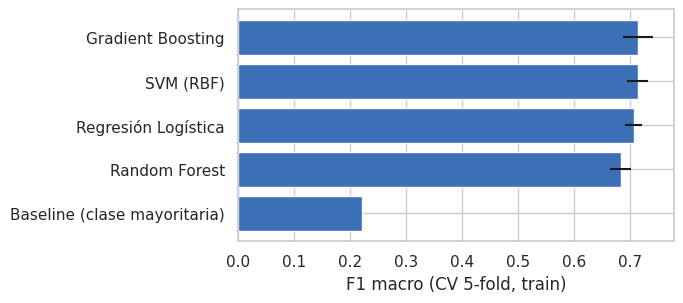

In [12]:
def armar_pipeline(clf):
    return Pipeline([("prep", clone(preprocesador)), ("clf", clf)])


MODELOS = {
    "Baseline (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión Logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    "SVM (RBF)": SVC(class_weight="balanced", probability=True, random_state=SEED),
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "recall_macro": "recall_macro"}

filas = []
for nombre, clf in MODELOS.items():
    r = cross_validate(armar_pipeline(clf), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    filas.append({"modelo": nombre,
                  **{f"{m}_media": r[f"test_{m}"].mean() for m in scoring},
                  "f1_macro_std": r["test_f1_macro"].std()})
tabla_cv = pd.DataFrame(filas).sort_values("f1_macro_media", ascending=False).round(4).reset_index(drop=True)
display(tabla_cv)

plt.figure(figsize=(7, 3.2))
plt.barh(tabla_cv["modelo"][::-1], tabla_cv["f1_macro_media"][::-1], xerr=tabla_cv["f1_macro_std"][::-1], color="#3b6fb6")
plt.xlabel(f"F1 macro (CV {CV_FOLDS}-fold, train)"); plt.tight_layout(); plt.show()

In [13]:
# Ajuste de hiperparámetros del mejor candidato (grilla pequeña y justificable)
GRIDS = {
    "Regresión Logística": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 3, 5]},
    "Gradient Boosting": {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [None, 3, 6],
                          "clf__max_leaf_nodes": [15, 31], "clf__l2_regularization": [0.0, 1.0]},
    "SVM (RBF)": {"clf__C": [0.5, 1, 5], "clf__gamma": ["scale", 0.01]},
}
candidatos = tabla_cv[tabla_cv["modelo"] != "Baseline (clase mayoritaria)"]
mejor_nombre = candidatos.iloc[0]["modelo"]
f1_sin_ajuste = candidatos.iloc[0]["f1_macro_media"]
print(f"Mejor en CV: {mejor_nombre} (F1 macro = {f1_sin_ajuste:.4f}) -> ajustando hiperparámetros...")

busqueda = GridSearchCV(armar_pipeline(clone(MODELOS[mejor_nombre])), GRIDS[mejor_nombre],
                        cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
busqueda.fit(X_train, y_train)
modelo_final = busqueda.best_estimator_
print("Mejores parámetros:", busqueda.best_params_)
print(f"F1 macro CV tras ajuste: {busqueda.best_score_:.4f}  (antes: {f1_sin_ajuste:.4f})")

Mejor en CV: Gradient Boosting (F1 macro = 0.7153) -> ajustando hiperparámetros...
Mejores parámetros: {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__max_leaf_nodes': 15}
F1 macro CV tras ajuste: 0.7307  (antes: 0.7153)


> **Ojo con la lectura:** la mejora por tuning suele ser pequeña y la CV del tuning es ligeramente optimista (se eligió el mejor de varias combinaciones sobre los mismos folds).
> El número que vale para reportar es el del **test**, que no se ha tocado hasta ahora.

## 5. Evaluación final en el set de prueba (se usa una sola vez)

In [14]:
y_pred = modelo_final.predict(X_test)
proba = modelo_final.predict_proba(X_test)
clases_modelo = list(modelo_final.classes_)

metricas_test = {
    "accuracy": accuracy_score(y_test, y_pred),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
    "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
    "recall_macro": recall_score(y_test, y_pred, average="macro"),
    "recall_dropout": recall_score(y_test, y_pred, labels=["Dropout"], average=None)[0],
    "roc_auc_ovr_macro": roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=clases_modelo),
}

base = armar_pipeline(MODELOS["Baseline (clase mayoritaria)"]).fit(X_train, y_train).predict(X_test)
metricas_baseline = {"accuracy": accuracy_score(y_test, base), "f1_macro": f1_score(y_test, base, average="macro")}

resumen = pd.DataFrame({
    "Modelo final": {k: round(v, 4) for k, v in metricas_test.items()},
    "Baseline": {**{k: round(v, 4) for k, v in metricas_baseline.items()}},
})
display(resumen)
print(f"CV (train) F1 macro = {busqueda.best_score_:.4f}  vs  TEST F1 macro = {metricas_test['f1_macro']:.4f}  "
      f"-> brecha {busqueda.best_score_ - metricas_test['f1_macro']:+.4f}")
print()
print(classification_report(y_test, y_pred, digits=3))

,Modelo final,Baseline
accuracy,0.7288,0.4994
f1_macro,0.6935,0.2221
f1_weighted,0.7424,NaN
recall_macro,0.7074,NaN
recall_dropout,0.6831,NaN
roc_auc_ovr_macro,0.8847,NaN


CV (train) F1 macro = 0.7307  vs  TEST F1 macro = 0.6935  -> brecha +0.0372

              precision    recall  f1-score   support

     Dropout      0.822     0.683     0.746       284
    Enrolled      0.419     0.654     0.511       159
    Graduate      0.865     0.785     0.823       442

    accuracy                          0.729       885
   macro avg      0.702     0.707     0.693       885
weighted avg      0.771     0.729     0.742       885



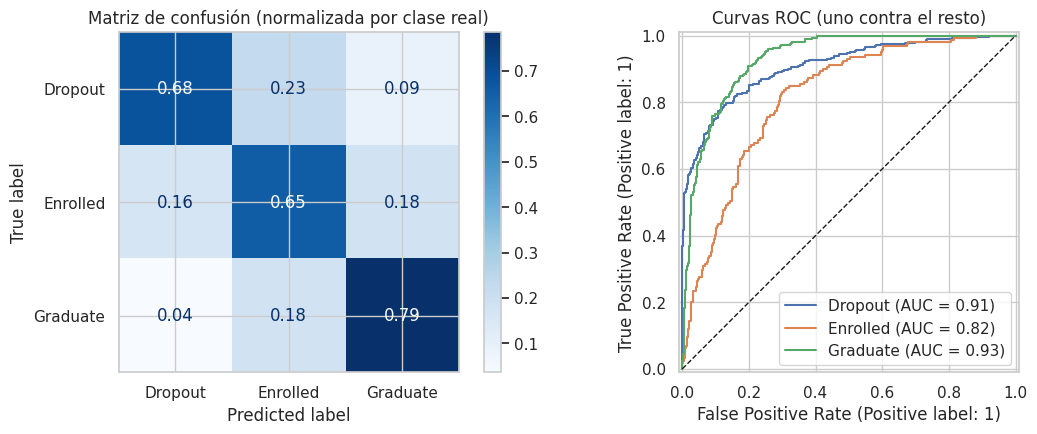

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", cmap="Blues", values_format=".2f", ax=ax[0])
ax[0].set_title("Matriz de confusión (normalizada por clase real)")
for i, c in enumerate(clases_modelo):
    RocCurveDisplay.from_predictions((y_test == c).astype(int), proba[:, i], name=c, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("Curvas ROC (uno contra el resto)")
plt.tight_layout(); plt.show()

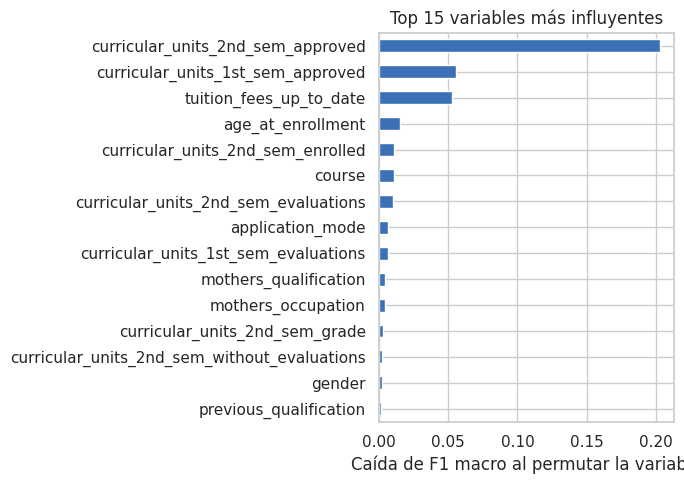

curricular_units_2nd_sem_approved       0.2030
curricular_units_1st_sem_approved       0.0557
tuition_fees_up_to_date                 0.0524
age_at_enrollment                       0.0151
curricular_units_2nd_sem_enrolled       0.0112
course                                  0.0110
curricular_units_2nd_sem_evaluations    0.0104
application_mode                        0.0068


In [16]:
# Interpretabilidad: importancia por permutación sobre el TEST (agrupa los one-hot en su variable original)
pi = permutation_importance(modelo_final, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
imp.head(15)[::-1].plot.barh(color="#3b6fb6")
plt.xlabel("Caída de F1 macro al permutar la variable"); plt.title("Top 15 variables más influyentes")
plt.tight_layout(); plt.show()
print(imp.head(8).round(4).to_string())

### Interpretación de resultados
   - Frente al baseline: todos lo superan por mucho (F1 macro ≈0,22 → ≈0,68–0,72 en CV).
   - Tres modelos equivalentes: Gradient Boosting (0,715), SVM (0,714) y regresión logística (0,707) quedan dentro de una desviación estándar (≈0,02); Random Forest queda más abajo (0,684). Se eligió Gradient Boosting por CV, pero la diferencia con SVM y regresión logística no es concluyente; la regresión logística es la más simple y explicable.
   - Generalización: en test, F1 macro 0,694, accuracy 0,729 y AUC 0,885. La brecha CV–test es 0,037, del orden del ruido esperable con 885 filas de test, y la CV tras el ajuste es algo optimista.
   - Dropout: precision 0,82 y recall 0,68. De cada 10 desertores reales detecta ≈7, y de cada 10 alertas ≈8 son correctas.
   - Enrolled es la clase débil (F1 0,51): el modelo la sobre-predice (recall 0,65, precision 0,42).
   - Variables más influyentes: unidades aprobadas del 2.º semestre (muy por encima del resto), unidades aprobadas del 1.er semestre y matrícula al día.

## 6. Artefactos (para usa en  Streamlit)
Se guarda el **pipeline completo** (preprocesamiento + modelo), no solo el modelo: la app debe enviarle un `DataFrame` con las columnas de `model_card.json` y nada más.

In [17]:
joblib.dump(modelo_final, ARTEFACTOS / "modelo_desercion.pkl", compress=3)   # compress: un Random Forest sin podar pesa >50 MB
df.to_csv(ARTEFACTOS / "dataset_procesado.csv", index=False)   # mismas filas, columnas renombradas

model_card = {
    "modelo": mejor_nombre,
    "mejores_parametros": busqueda.best_params_,
    "clases": clases_modelo,
    "usar_2do_sem": USAR_2DO_SEM,
    "semilla": SEED,
    "columnas_entrada": FEATURES,
    "nominales": {c: sorted(int(v) for v in X[c].unique()) for c in COL_NOMINALES},
    "binarias": COL_BINARIAS,
    "numericas": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "mediana": float(X[c].median())} for c in COL_NUMERICAS},
    "metricas_test": {k: round(float(v), 4) for k, v in metricas_test.items()},
    "metricas_cv_f1_macro": round(float(busqueda.best_score_), 4),
    "mapa_columnas_original_a_snake": mapa_columnas,
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
(ARTEFACTOS / "model_card.json").write_text(json.dumps(model_card, indent=2, ensure_ascii=False), encoding="utf-8")
(ARTEFACTOS / "requirements_modelo.txt").write_text(
    f"scikit-learn=={sklearn.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\n")
print("Guardado en", ARTEFACTOS.resolve())
for p in sorted(ARTEFACTOS.iterdir()):
    print(f" - {p.name} ({p.stat().st_size/1024:.0f} KB)")

Guardado en /content/artefactos
 - dataset_procesado.csv (516 KB)
 - model_card.json (8 KB)
 - modelo_desercion.pkl (84 KB)
 - requirements_modelo.txt (0 KB)


In [18]:
# Prueba de humo: cargar el .pkl como lo hará Streamlit y predecir
modelo_cargado = joblib.load(ARTEFACTOS / "modelo_desercion.pkl")
muestra = X_test.sample(3, random_state=SEED)
salida = pd.DataFrame(modelo_cargado.predict_proba(muestra), columns=modelo_cargado.classes_, index=muestra.index).round(3)
salida["prediccion"] = modelo_cargado.predict(muestra)
salida["real"] = y_test.loc[muestra.index]
display(salida)

# Un código de categoría nunca visto NO debe romper la app
fila = X_test.iloc[[0]].copy(); fila["course"] = 99999
print("Categoría desconocida ->", modelo_cargado.predict(fila)[0], "(sin error)")

,Dropout,Enrolled,Graduate,prediccion,real
2873,0.185,0.144,0.671,Graduate,Graduate
891,0.852,0.032,0.115,Dropout,Dropout
3799,0.976,0.023,0.001,Dropout,Dropout


Categoría desconocida -> Graduate (sin error)


In [19]:
# Descarga de artefactos (solo Colab). Fuera de Colab quedan en ./artefactos
try:
    import shutil
    from google.colab import files
    shutil.make_archive("artefactos_modelo", "zip", ARTEFACTOS)
    files.download("artefactos_modelo.zip")
except ImportError:
    print("Fuera de Colab: los archivos ya están en ./artefactos")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Limitaciones y pendientes

1. **Predicción tardía (decisión clave del grupo).** La variable más influyente es del 2.º semestre: con `USAR_2DO_SEM = True` el modelo detecta la deserción cuando ya casi ocurrió. Con `False` (solo hasta el 1.er semestre), la corrida de referencia bajó el F1 macro en test de ≈0,72 a ≈0,67 y el recall de *Dropout* de ≈0,72 a ≈0,69. Recomendación: reportar **ambas** versiones en el póster y presentar la preventiva como la útil en la práctica.
2. **Ajuste de hiperparámetros:** la CV del ajuste es algo optimista; solo cuenta el resultado en test.
3. **Sesgo y ética:** el modelo usa género, nacionalidad, estado civil y ocupación de los padres. Usarlo para decidir sobre estudiantes concretos exige una revisión de equidad; como mínimo, declararlo como limitación.
4. **Alcance:** los datos vienen de una sola institución; no se puede asumir que generalicen a otros contextos sin revalidar.
5. **El `.pkl` depende de la versión de librerías:** la app de Streamlit debe instalar las versiones de `requirements_modelo.txt`; si no, `joblib.load` puede fallar o dar resultados distintos.
6. **Pendiente para Streamlit:** el CSV trae códigos (p. ej. `course = 9500`) sin etiquetas. El diccionario de códigos está en la ficha del dataset en UCI y hay que tomarlo de allí para mostrar nombres legibles; no se incluye aquí porque no viene en los datos.
7. **Pendiente del grupo:** EDA visual, póster APA 7 y video de sustentación.